In [2]:
import copy
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.11.0+cpu | device: cpu


In [3]:
CATEGORIES = ["rec.autos", "rec.motorcycles"]
# remove headers, footers, and quoted replies to reduce metadata leakage
data = fetch_20newsgroups(
    subset="all", categories=CATEGORIES, remove=("headers", "footers", "quotes"),
    shuffle=True, random_state=SEED
)
texts = np.asarray(data.data, dtype=object)
labels = np.asarray(data.target, dtype=np.int64)
class_names = list(data.target_names)
print(f"Examples: {len(texts):,}")
print(pd.Series([class_names[i] for i in labels]).value_counts())

# 70% train, 15% validation, 15% test. The test set stays untouched until evaluation.
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    texts, labels, test_size=0.30, random_state=SEED, stratify=labels
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)
print(f"Train: {len(y_train):,} | validation: {len(y_val):,} | test: {len(y_test):,}")

Examples: 1,986
rec.motorcycles    996
rec.autos          990
Name: count, dtype: int64
Train: 1,390 | validation: 298 | test: 298


In [4]:
# Fit only on training text. Word n-grams capture phrases; character n-grams help with spelling/word variants.
vectorizer = TfidfVectorizer(
    lowercase=True, stop_words="english", max_features=30000,
    ngram_range=(1, 2), min_df=2, sublinear_tf=True, dtype=np.float32
)
X_train = vectorizer.fit_transform(X_train_text).toarray()
X_val = vectorizer.transform(X_val_text).toarray()
X_test = vectorizer.transform(X_test_text).toarray()
print(f"TF-IDF feature count: {X_train.shape[1]:,}")
print(f"Dense train matrix: {X_train.nbytes / 1024**2:.1f} MiB")

TF-IDF feature count: 10,704
Dense train matrix: 56.8 MiB


In [5]:
def make_loader(features, targets, batch_size=64, shuffle=False):
    x = torch.tensor(features, dtype=torch.float32)
    y = torch.tensor(targets, dtype=torch.long)
    return DataLoader(TensorDataset(x, y), batch_size=batch_size, shuffle=shuffle)

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val)
test_loader = make_loader(X_test, y_test)

class TextClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.40),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        return self.network(x)

model = TextClassifier(X_train.shape[1], len(class_names)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
print(model)

TextClassifier(
  (network): Sequential(
    (0): Linear(in_features=10704, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=512, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.25, inplace=False)
    (8): Linear(in_features=128, out_features=2, bias=True)
  )
)


In [6]:
def run_epoch(loader, training):
    model.train(training)
    total_loss, all_preds, all_targets = 0.0, [], []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for features, targets in loader:
            features, targets = features.to(DEVICE), targets.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(features)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(targets)
            all_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())
            all_targets.extend(targets.detach().cpu().numpy())
    return total_loss / len(loader.dataset), accuracy_score(all_targets, all_preds)

MAX_EPOCHS = 30
PATIENCE = 4
history = {"train_loss": [], "val_loss": [], "train_accuracy": [], "val_accuracy": []}
best_val_loss, best_state, stale_epochs = float("inf"), None, 0
start = time.time()

for epoch in range(1, MAX_EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_accuracy"].append(train_acc)
    history["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch:02d}/{MAX_EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.3f} "
          f"| val loss {val_loss:.4f}, acc {val_acc:.3f}")
    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        stale_epochs = 0
    else:
        stale_epochs += 1
        if stale_epochs >= PATIENCE:
            print(f"Early stopping: validation loss did not improve for {PATIENCE} epochs.")
            break

model.load_state_dict(best_state)
print(f"Best validation loss: {best_val_loss:.4f} | elapsed: {time.time()-start:.1f}s")

Epoch 01/30 | train loss 0.4561, acc 0.780 | val loss 0.6681, acc 0.497
Epoch 02/30 | train loss 0.1231, acc 0.973 | val loss 0.5149, acc 0.775
Epoch 03/30 | train loss 0.0560, acc 0.985 | val loss 0.3509, acc 0.846
Epoch 04/30 | train loss 0.0404, acc 0.984 | val loss 0.3317, acc 0.859
Epoch 05/30 | train loss 0.0427, acc 0.984 | val loss 0.3787, acc 0.839
Epoch 06/30 | train loss 0.0373, acc 0.981 | val loss 0.3386, acc 0.842
Epoch 07/30 | train loss 0.0332, acc 0.982 | val loss 0.3369, acc 0.839
Epoch 08/30 | train loss 0.0362, acc 0.982 | val loss 0.3347, acc 0.842
Early stopping: validation loss did not improve for 4 epochs.
Best validation loss: 0.3317 | elapsed: 14.5s


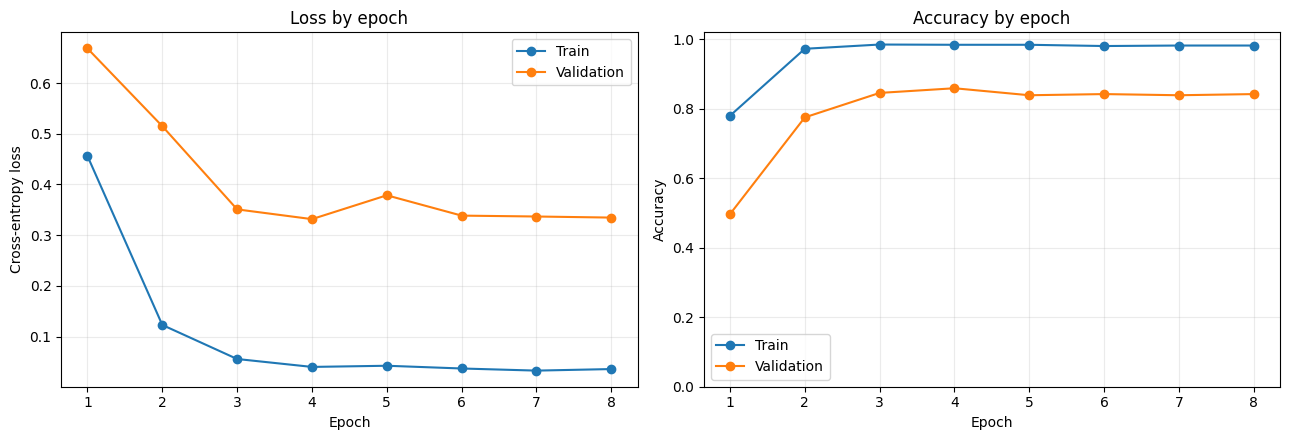

In [7]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set(title="Loss by epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set(title="Accuracy by epoch", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.02))
axes[1].legend(); axes[1].grid(alpha=.25)
plt.tight_layout()
plt.show()

Test loss: 0.2943
Test accuracy: 0.8523
                 precision    recall  f1-score   support

      rec.autos     0.8144    0.9128    0.8608       149
rec.motorcycles     0.9008    0.7919    0.8429       149

       accuracy                         0.8523       298
      macro avg     0.8576    0.8523    0.8518       298
   weighted avg     0.8576    0.8523    0.8518       298



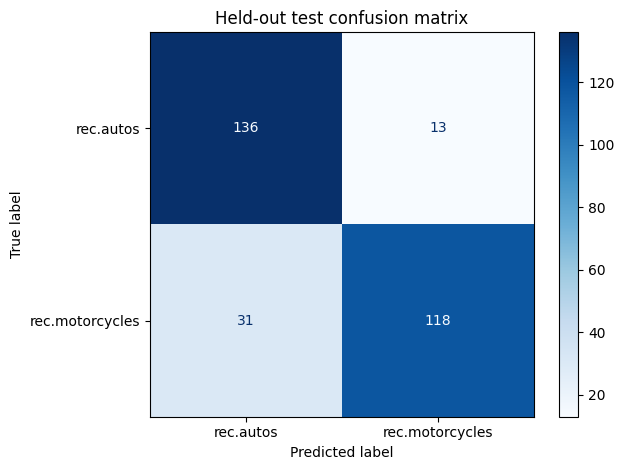

In [8]:
test_loss, _ = run_epoch(test_loader, training=False)
model.eval()
with torch.no_grad():
    test_logits = model(torch.tensor(X_test, dtype=torch.float32, device=DEVICE))
    test_probs = torch.softmax(test_logits, dim=1).cpu().numpy()
test_preds = test_probs.argmax(axis=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {accuracy_score(y_test, test_preds):.4f}")
print(classification_report(y_test, test_preds, target_names=class_names, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, test_preds, display_labels=class_names, cmap="Blues")
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

In [12]:
def predict_text(samples):
    """Return the predicted category and softmax confidence for each input string."""
    if isinstance(samples, str):
        samples = [samples]
    features = vectorizer.transform(samples).toarray()
    model.eval()
    with torch.no_grad():
        logits = model(torch.tensor(features, dtype=torch.float32, device=DEVICE))
        probabilities = torch.softmax(logits, dim=1).cpu().numpy()
    rows = []
    for text, probs in zip(samples, probabilities):
        idx = int(np.argmax(probs))
        rows.append({
            "text": text,
            "predicted_topic": class_names[idx],
            "confidence": float(probs[idx]),
            **{f"P({name})": float(probs[i]) for i, name in enumerate(class_names)},
        })
    return pd.DataFrame(rows)

sample_posts = [
    "I need advice about choosing a reliable used car and improving fuel economy.",
    "What tires and riding gear do you recommend for a long motorcycle trip?",
    "My engine makes a strange noise when accelerating; could the transmission be involved?",
    "Looking for recommendations on a comfortable touring bike and helmet.",
]
predict_text(sample_posts).round(4)

,text,predicted_topic,confidence,P(rec.autos),P(rec.motorcycles)
0,I need advice about choosing a reliable used c...,rec.autos,0.9717,0.9717,0.0283
1,What tires and riding gear do you recommend fo...,rec.motorcycles,0.9886,0.0114,0.9886
2,My engine makes a strange noise when accelerat...,rec.motorcycles,0.5328,0.4672,0.5328
3,Looking for recommendations on a comfortable t...,rec.motorcycles,0.9898,0.0102,0.9898


In [13]:
import pickle
from pathlib import Path

artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)
torch.save({
    "model_state_dict": model.cpu().state_dict(),
    "input_dim": X_train.shape[1],
    "class_names": class_names,
}, artifact_dir / "text_classifier.pt")
with open(artifact_dir / "tfidf_vectorizer.pkl", "wb") as f:
    pickle.dump(vectorizer, f)
print(f"Saved model and vectorizer in {artifact_dir.resolve()}")

Saved model and vectorizer in /content/artifacts
